# AIML Internal Assessment
## Web Scraping, Data Preprocessing and Feature Engineering

**Dataset source:** (https://www.scrapethissite.com/pages/forms/) — Hockey Teams  
**Tools:** Python, Requests, BeautifulSoup, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

**Student Name:** Samarth Subhash Kadam  
**PRN:** 202401040131  
**Division:** A  
**Roll No.:** 33  
**Subject:** Artificial Intelligence and Machine Learning

## 1. Introduction

This assignment collects hockey-team statistics from Scrape This Site, explores and cleans the data, engineers new features, detects outliers, scales numerical data, visualizes patterns, and trains a Random Forest model.

### Objectives
1. Scrape team statistics from multiple pages.
2. Save the original dataset as a CSV file.
3. Perform exploratory data analysis (EDA).
4. Demonstrate handling missing values and duplicates.
5. Convert fields to appropriate data types.
6. Detect and cap numerical outliers using the IQR method.
7. Create useful features and a classification target.
8. Apply standardization and Min-Max scaling.
9. Create visualizations and descriptive statistics.
10. Train and evaluate a classification model.

## 2. Web Scraping

The Hockey Teams page contains team statistics by season. The scraper reads the table rows and follows pagination links when present. If the site layout changes, inspect the page's HTML and update the selectors.

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

BASE_URL = "https://www.scrapethissite.com/pages/forms/"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; educational data collection)"}
response = requests.get(BASE_URL, headers=HEADERS, timeout=30)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")
print("Page title:", soup.title.get_text(" ", strip=True) if soup.title else "No title")
print("HTTP status:", response.status_code)

Page title: Hockey Teams: Forms, Searching and Pagination | Scrape This Site | A public sandbox for learning web scraping
HTTP status: 200


In [ ]:
def parse_team_rows(page_soup):
    """Extract hockey team rows from the page table."""
    rows = []
    for tr in page_soup.select("tr.team"):
        def cell(selector):
            tag = tr.select_one(selector)
            return tag.get_text(" ", strip=True) if tag else None

        rows.append({
            "Team": cell(".name"),
            "Year": cell(".year"),
            "Wins": cell(".wins"),
            "Losses": cell(".losses"),
            "OT_Losses": cell(".ot-losses"),
            "Win_Percentage": cell(".pct"),
            "Goals_For": cell(".gf"),
            "Goals_Against": cell(".ga"),
            "Goal_Difference": cell(".diff")
        })
    return rows

records = []
max_pages = 30

for page_number in range(1, max_pages + 1):
    page_url = BASE_URL if page_number == 1 else f"{BASE_URL}?page_num={page_number}"
    page_response = requests.get(page_url, headers=HEADERS, timeout=30)
    page_response.raise_for_status()
    page_soup = BeautifulSoup(page_response.text, "html.parser")
    page_records = parse_team_rows(page_soup)

    if not page_records:
        if page_number == 1:
            raise ValueError("No hockey team rows found. Please inspect the website HTML/selectors.")
        break

    records.extend(page_records)
    time.sleep(0.2)

raw_df = pd.DataFrame(records).drop_duplicates()
if raw_df.empty:
    raise ValueError("Scraping returned no records.")
raw_df.to_csv("raw_hockey_teams.csv", index=False)
print("Raw dataset saved: raw_hockey_teams.csv")
print("Shape:", raw_df.shape)
display(raw_df.head())

Raw dataset saved: raw_hockey_teams.csv
Shape: (582, 9)


,Team,Year,Wins,Losses,OT_Losses,Win_Percentage,Goals_For,Goals_Against,Goal_Difference
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25


## 3. Exploratory Data Analysis (EDA)

Review the first and last rows, dataset dimensions, data types, missing values, duplicates, and summary statistics before cleaning.

In [ ]:
display(raw_df.head())
display(raw_df.tail())
print("Dataset shape:", raw_df.shape)
raw_df.info()
print("\nMissing values:")
display(raw_df.isna().sum().to_frame("Missing_Count"))
print("Duplicate rows:", raw_df.duplicated().sum())
display(raw_df.describe(include="all").T)

,Team,Year,Wins,Losses,OT_Losses,Win_Percentage,Goals_For,Goals_Against,Goal_Difference
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25


,Team,Year,Wins,Losses,OT_Losses,Win_Percentage,Goals_For,Goals_Against,Goal_Difference
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10,0.451,225,246,-21


Dataset shape: (582, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Team             582 non-null    object
 1   Year             582 non-null    object
 2   Wins             582 non-null    object
 3   Losses           582 non-null    object
 4   OT_Losses        582 non-null    object
 5   Win_Percentage   582 non-null    object
 6   Goals_For        582 non-null    object
 7   Goals_Against    582 non-null    object
 8   Goal_Difference  582 non-null    object
dtypes: object(9)
memory usage: 41.1+ KB

Missing values:


,Missing_Count
Team,0
Year,0
Wins,0
Losses,0
OT_Losses,0
Win_Percentage,0
Goals_For,0
Goals_Against,0
Goal_Difference,0


Duplicate rows: 0


,count,unique,top,freq
Team,582,35,Boston Bruins,21
Year,582,21,2007,30
Wins,582,47,43,30
Losses,582,47,27,35
OT_Losses,582,19,,224
Win_Percentage,582,94,0.5,30
Goals_For,582,172,214,13
Goals_Against,582,169,231,11
Goal_Difference,582,178,35,13


## 4. Simulate Data Quality Issues

To demonstrate preprocessing, create a working copy and introduce a small number of missing values and duplicate rows. The original scraped dataset remains unchanged. A synthetic extreme value is also added for demonstration and is treated in the outlier section.

In [ ]:
problem_df = raw_df.copy()
numeric_source = "Goals_For"
# Convert a copy of the selected numeric field so controlled test values can be inserted.
problem_df[numeric_source] = pd.to_numeric(problem_df[numeric_source], errors="coerce")
rng = np.random.default_rng(42)

if len(problem_df) >= 10:
    missing_rows = rng.choice(problem_df.index, size=min(3, len(problem_df)//10), replace=False)
    problem_df.loc[missing_rows, numeric_source] = np.nan
    problem_df = pd.concat([problem_df, problem_df.iloc[[0]]], ignore_index=True)

print("Rows after simulated issues:", len(problem_df))
print("Missing values introduced/current:", int(problem_df.isna().sum().sum()))
print("Duplicate rows:", int(problem_df.duplicated().sum()))

Rows after simulated issues: 583
Missing values introduced/current: 3
Duplicate rows: 1


## 5. Data Cleaning and Type Conversion

Numeric fields are converted with `to_numeric`. Missing numeric values are filled with the median, while missing team names are filled with a placeholder. Duplicate rows are removed.

In [ ]:
clean_df = problem_df.copy()
numeric_cols = ["Year", "Wins", "Losses", "OT_Losses", "Win_Percentage",
                "Goals_For", "Goals_Against", "Goal_Difference"]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

for col in numeric_cols:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

clean_df["Team"] = clean_df["Team"].fillna("Unknown").astype(str).str.strip()
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

print("Shape after cleaning:", clean_df.shape)
print("Missing values remaining:", int(clean_df.isna().sum().sum()))
print("Duplicate rows remaining:", int(clean_df.duplicated().sum()))
display(clean_df.head())

Shape after cleaning: (582, 9)
Missing values remaining: 0
Duplicate rows remaining: 0


,Team,Year,Wins,Losses,OT_Losses,Win_Percentage,Goals_For,Goals_Against,Goal_Difference
0,Boston Bruins,1990,44,24,7.0,0.550,299.0,264,35
1,Buffalo Sabres,1990,31,30,7.0,0.388,292.0,278,14
2,Calgary Flames,1990,46,26,7.0,0.575,344.0,263,81
3,Chicago Blackhawks,1990,49,23,7.0,0.613,284.0,211,73
4,Detroit Red Wings,1990,34,38,7.0,0.425,273.0,298,-25


## 6. Feature Engineering

Create features that make the dataset easier to analyze and use in a model:

- **Win_Percentage_Class:** high or low win percentage, split at the median.
- **Total_Games:** wins + losses + overtime losses.
- **Scoring_Efficiency:** goals scored divided by total goals scored and conceded.
- **Goal_Difference_Recalculated:** goals for minus goals against.
- **Team_Code:** numerical code for the team name, used as a model input.

The target is created from win percentage. The original win percentage is excluded from model inputs to avoid target leakage.

In [ ]:
clean_df["Total_Games"] = clean_df["Wins"] + clean_df["Losses"] + clean_df["OT_Losses"]
total_goals = clean_df["Goals_For"] + clean_df["Goals_Against"]
clean_df["Scoring_Efficiency"] = np.where(total_goals > 0, clean_df["Goals_For"] / total_goals, 0)
clean_df["Goal_Difference_Recalculated"] = clean_df["Goals_For"] - clean_df["Goals_Against"]

median_win_pct = clean_df["Win_Percentage"].median()
clean_df["Win_Percentage_Class"] = np.where(
    clean_df["Win_Percentage"] >= median_win_pct, "High", "Low"
)
clean_df["Team_Code"] = clean_df["Team"].astype("category").cat.codes

display(clean_df[["Team", "Year", "Win_Percentage", "Win_Percentage_Class",
                  "Total_Games", "Scoring_Efficiency", "Team_Code"]].head())
print(clean_df["Win_Percentage_Class"].value_counts())

,Team,Year,Win_Percentage,Win_Percentage_Class,Total_Games,Scoring_Efficiency,Team_Code
0,Boston Bruins,1990,0.550,High,75.0,0.531083,2
1,Buffalo Sabres,1990,0.388,Low,68.0,0.512281,3
2,Calgary Flames,1990,0.575,High,79.0,0.566722,4
3,Chicago Blackhawks,1990,0.613,High,79.0,0.573737,6
4,Detroit Red Wings,1990,0.425,Low,79.0,0.478109,10


Win_Percentage_Class
High    309
Low     273
Name: count, dtype: int64


## 7. Outlier Detection and Treatment (IQR)

For goals scored, calculate Q1, Q3, IQR, and the lower/upper bounds. Values outside the bounds are potential outliers. Use capping rather than deleting rows so that records are preserved.

Q1: 211.0 Q3: 254.0 IQR: 43.0
Lower bound: 146.5 Upper bound: 318.5
Potential outliers before capping: 40


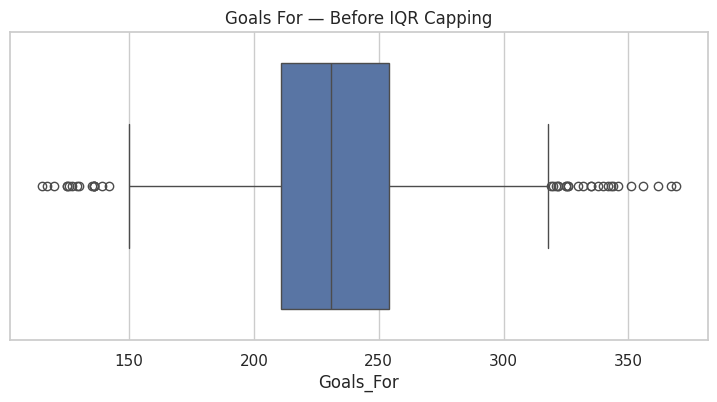

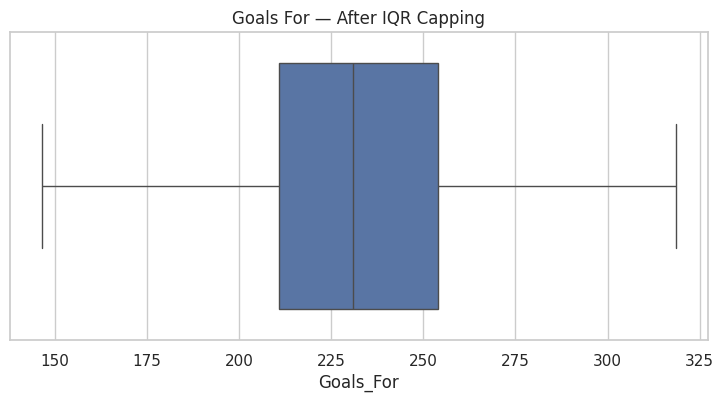

In [ ]:
outlier_col = "Goals_For"
q1 = clean_df[outlier_col].quantile(0.25)
q3 = clean_df[outlier_col].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_mask = (clean_df[outlier_col] < lower_bound) | (clean_df[outlier_col] > upper_bound)

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Lower bound:", lower_bound, "Upper bound:", upper_bound)
print("Potential outliers before capping:", int(outlier_mask.sum()))

plt.figure(figsize=(9, 4))
sns.boxplot(x=clean_df[outlier_col])
plt.title("Goals For — Before IQR Capping")
plt.show()

clean_df[outlier_col] = clean_df[outlier_col].clip(lower=lower_bound, upper=upper_bound)

plt.figure(figsize=(9, 4))
sns.boxplot(x=clean_df[outlier_col])
plt.title("Goals For — After IQR Capping")
plt.show()

## 8. Statistical Analysis

Calculate mean, median, mode, variance, standard deviation, minimum, maximum, and range for a numerical feature.

In [ ]:
series = clean_df["Goals_For"]
stats_df = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Mode", "Variance", "Standard Deviation", "Minimum", "Maximum", "Range"],
    "Value": [series.mean(), series.median(), series.mode().iloc[0], series.var(),
              series.std(), series.min(), series.max(), series.max() - series.min()]
})
display(stats_df)

,Statistic,Value
0,Mean,233.634021
1,Median,231.000000
2,Mode,318.500000
3,Variance,1390.201457
4,Standard Deviation,37.285405
5,Minimum,146.500000
6,Maximum,318.500000
7,Range,172.000000


## 9. Feature Scaling

Standardization transforms values to have approximately zero mean and unit standard deviation. Min-Max scaling maps values to the interval [0, 1]. These are demonstrated on selected numerical features.

In [ ]:
scale_cols = ["Goals_For", "Goals_Against", "Goal_Difference_Recalculated", "Total_Games"]
scaling_data = clean_df[scale_cols].copy()

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
standardized = pd.DataFrame(standard_scaler.fit_transform(scaling_data), columns=[c + "_Z" for c in scale_cols])
normalized = pd.DataFrame(minmax_scaler.fit_transform(scaling_data), columns=[c + "_MinMax" for c in scale_cols])

display(pd.concat([scaling_data.head(), standardized.head(), normalized.head()], axis=1))
print("Standardized means (approximately 0):")
print(standardized.mean().round(4))
print("Min-Max minimums:")
print(normalized.min().round(4))
print("Min-Max maximums:")
print(normalized.max().round(4))

,Goals_For,Goals_Against,Goal_Difference_Recalculated,Total_Games,Goals_For_Z,Goals_Against_Z,Goal_Difference_Recalculated_Z,Total_Games_Z,Goals_For_MinMax,Goals_Against_MinMax,Goal_Difference_Recalculated_MinMax,Total_Games_MinMax
0,299.0,264,35.0,75.0,1.754633,0.704815,0.774807,-0.206928,0.886628,0.498328,0.679412,0.695652
1,292.0,278,14.0,68.0,1.566731,1.034427,0.311469,-1.123258,0.845930,0.545151,0.617647,0.543478
2,318.5,263,81.0,79.0,2.278076,0.681271,1.789736,0.316689,1.000000,0.494983,0.814706,0.782609
3,284.0,211,73.0,79.0,1.351985,-0.543002,1.613227,0.316689,0.799419,0.321070,0.791176,0.782609
4,273.0,298,-25.0,79.0,1.056710,1.505301,-0.549014,0.316689,0.735465,0.612040,0.502941,0.782609


Standardized means (approximately 0):
Goals_For_Z                       0.0
Goals_Against_Z                  -0.0
Goal_Difference_Recalculated_Z    0.0
Total_Games_Z                     0.0
dtype: float64
Min-Max minimums:
Goals_For_MinMax                       0.0
Goals_Against_MinMax                   0.0
Goal_Difference_Recalculated_MinMax    0.0
Total_Games_MinMax                     0.0
dtype: float64
Min-Max maximums:
Goals_For_MinMax                       1.0
Goals_Against_MinMax                   1.0
Goal_Difference_Recalculated_MinMax    1.0
Total_Games_MinMax                     1.0
dtype: float64


## 10. Data Visualization

The following charts show the distribution of goals, wins by class, relationships between scoring and win percentage, correlations among numerical features, and average win percentage by season.

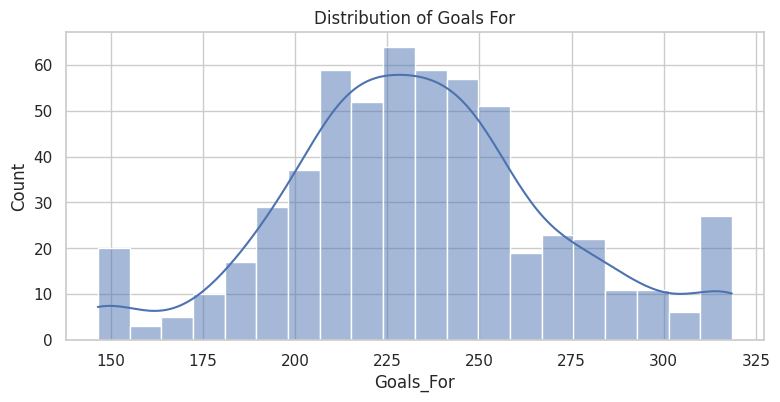

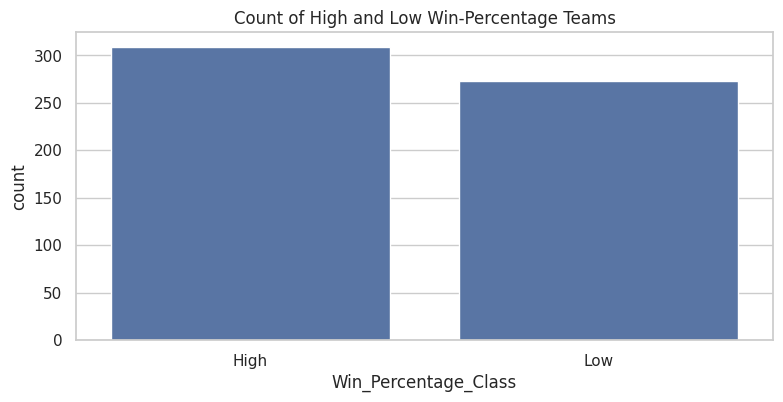

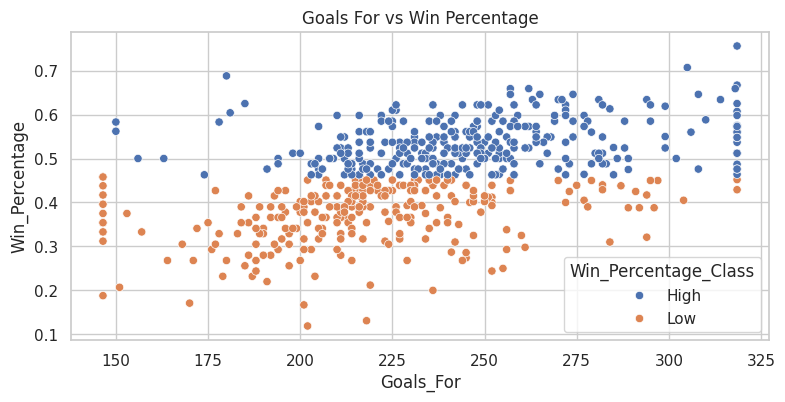

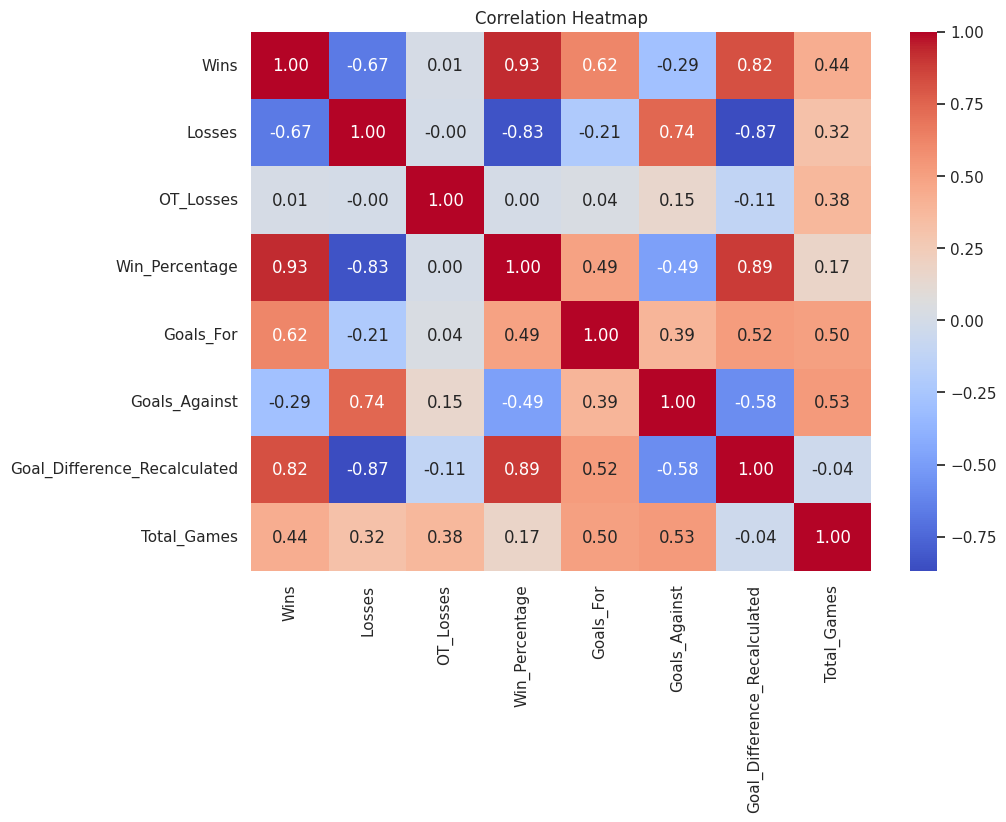

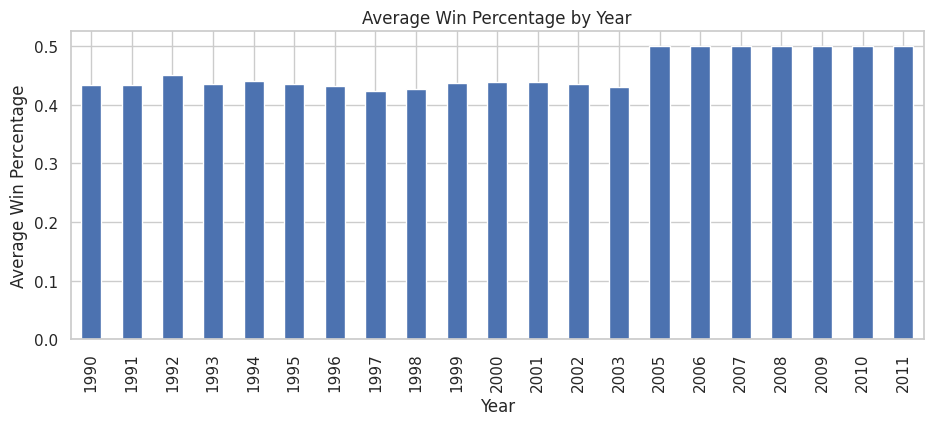

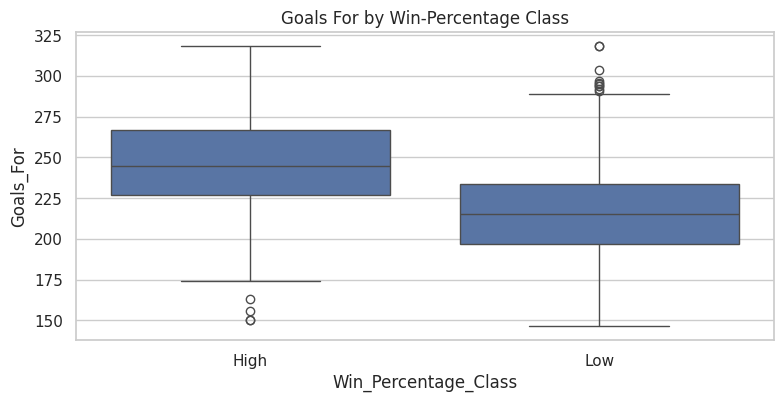

In [ ]:
plt.figure(figsize=(9, 4))
sns.histplot(clean_df["Goals_For"], bins=20, kde=True)
plt.title("Distribution of Goals For")
plt.show()

plt.figure(figsize=(9, 4))
sns.countplot(data=clean_df, x="Win_Percentage_Class")
plt.title("Count of High and Low Win-Percentage Teams")
plt.show()

plt.figure(figsize=(9, 4))
sns.scatterplot(data=clean_df, x="Goals_For", y="Win_Percentage", hue="Win_Percentage_Class")
plt.title("Goals For vs Win Percentage")
plt.show()

corr_cols = ["Wins", "Losses", "OT_Losses", "Win_Percentage", "Goals_For",
             "Goals_Against", "Goal_Difference_Recalculated", "Total_Games"]
plt.figure(figsize=(10, 7))
sns.heatmap(clean_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

avg_by_year = clean_df.groupby("Year")["Win_Percentage"].mean().sort_index()
plt.figure(figsize=(11, 4))
avg_by_year.plot(kind="bar")
plt.title("Average Win Percentage by Year")
plt.ylabel("Average Win Percentage")
plt.show()

plt.figure(figsize=(9, 4))
sns.boxplot(data=clean_df, x="Win_Percentage_Class", y="Goals_For")
plt.title("Goals For by Win-Percentage Class")
plt.show()

## 11. Machine Learning — Random Forest Classifier

Predict whether a team's win percentage is High or Low using team code, season, goals for/against, goal difference, and total games. `Win_Percentage` is not used as an input because it directly determines the target class.

Target distribution:


,count
Win_Percentage_Class,
High,309
Low,273


Accuracy: 0.906

Classification report:
              precision    recall  f1-score   support

        High       0.93      0.89      0.91        62
         Low       0.88      0.93      0.90        55

    accuracy                           0.91       117
   macro avg       0.91      0.91      0.91       117
weighted avg       0.91      0.91      0.91       117



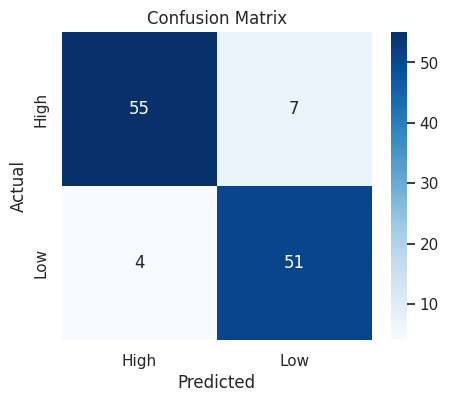

,Feature,Importance
6,Scoring_Efficiency,0.303955
4,Goal_Difference_Recalculated,0.300535
2,Goals_For,0.101671
3,Goals_Against,0.092311
5,Total_Games,0.085678
1,Year,0.080584
0,Team_Code,0.035265


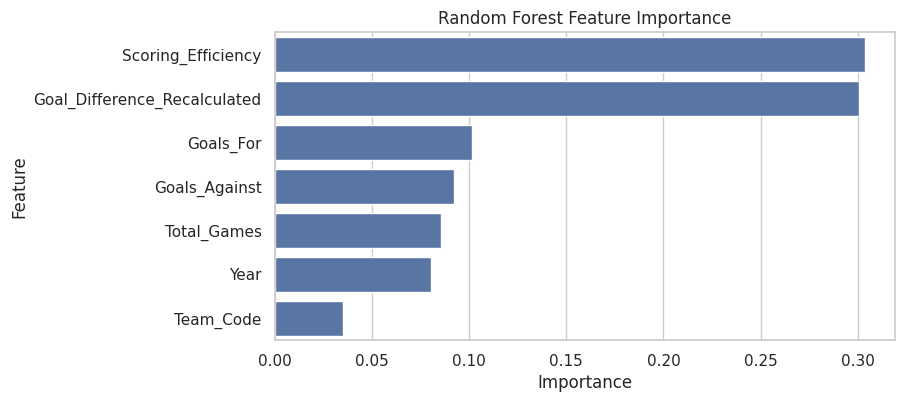

In [ ]:
ml_df = clean_df.copy()
feature_columns = ["Team_Code", "Year", "Goals_For", "Goals_Against",
                   "Goal_Difference_Recalculated", "Total_Games", "Scoring_Efficiency"]
X = ml_df[feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0)
y = ml_df["Win_Percentage_Class"]

print("Target distribution:")
display(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = ["High", "Low"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)
display(importance_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.show()

## 12. Save and Verify the Final Dataset

Save the cleaned dataset, including the engineered features, as a CSV file. Review the final dimensions, data types, missing values, and duplicates.

In [ ]:
final_df = clean_df.copy()
final_df.to_csv("cleaned_hockey_teams.csv", index=False)

print("Final dataset saved as cleaned_hockey_teams.csv")
print("Rows:", final_df.shape[0])
print("Columns:", final_df.shape[1])
print("Missing values:", int(final_df.isna().sum().sum()))
print("Duplicate rows:", int(final_df.duplicated().sum()))
print("\nColumns:")
print(final_df.columns.tolist())
display(final_df.head(10))

Final dataset saved as cleaned_hockey_teams.csv
Rows: 582
Columns: 14
Missing values: 0
Duplicate rows: 0

Columns:
['Team', 'Year', 'Wins', 'Losses', 'OT_Losses', 'Win_Percentage', 'Goals_For', 'Goals_Against', 'Goal_Difference', 'Total_Games', 'Scoring_Efficiency', 'Goal_Difference_Recalculated', 'Win_Percentage_Class', 'Team_Code']


,Team,Year,Wins,Losses,OT_Losses,Win_Percentage,Goals_For,Goals_Against,Goal_Difference,Total_Games,Scoring_Efficiency,Goal_Difference_Recalculated,Win_Percentage_Class,Team_Code
0,Boston Bruins,1990,44,24,7.0,0.550,299.0,264,35,75.0,0.531083,35.0,High,2
1,Buffalo Sabres,1990,31,30,7.0,0.388,292.0,278,14,68.0,0.512281,14.0,Low,3
2,Calgary Flames,1990,46,26,7.0,0.575,318.5,263,81,79.0,0.566722,81.0,High,4
3,Chicago Blackhawks,1990,49,23,7.0,0.613,284.0,211,73,79.0,0.573737,73.0,High,6
4,Detroit Red Wings,1990,34,38,7.0,0.425,273.0,298,-25,79.0,0.478109,-25.0,Low,10
5,Edmonton Oilers,1990,37,37,7.0,0.463,272.0,272,0,81.0,0.500000,0.0,High,11
6,Hartford Whalers,1990,31,38,7.0,0.388,238.0,276,-38,76.0,0.463035,-38.0,Low,13
7,Los Angeles Kings,1990,46,24,7.0,0.575,318.5,254,86,77.0,0.572391,86.0,High,14
8,Minnesota North Stars,1990,27,39,7.0,0.338,256.0,266,-10,73.0,0.490421,-10.0,Low,16
9,Montreal Canadiens,1990,39,30,7.0,0.487,273.0,249,24,76.0,0.522989,24.0,High,18


In [ ]:
from google.colab import files

files.download("cleaned_hockey_teams.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Conclusion

This assignment demonstrates a complete data-science workflow using the Hockey Teams dataset from Scrape This Site. Data was collected with Requests and BeautifulSoup, inspected with EDA, cleaned, transformed, and enriched with derived features. IQR capping was used to reduce the influence of extreme values. Standardization and Min-Max scaling were demonstrated, visualizations were generated, and a Random Forest classifier was evaluated using a train-test split, accuracy, a classification report, and a confusion matrix.